# Detecção de anomalias

O enunciado pede detecção de anomalias em três tipos de dado:

| Dado | Técnica | Por quê |
|---|---|---|
| Sinais vitais (série temporal) | Limites clínicos + **Isolation Forest** | Muitos dados, padrão normal pode ser aprendido |
| Prescrições | **Regras** explícitas | Poucos registros por paciente; a equipe precisa saber exatamente o motivo do alerta |
| Movimentação do paciente | **Regras** sobre a trajetória do YOLOv8 | Situações bem definidas: parado demais, fora da área, ausente |

Para baixar os sinais vitais: `python scripts/baixar_dados.py bidmc`

In [1]:
import os
import sys
from pathlib import Path

RAIZ = Path.cwd() if (Path.cwd() / "src").exists() else Path.cwd().parent
os.chdir(RAIZ)
sys.path.insert(0, str(RAIZ))

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from src.anomalias.movimentacao import detectar_anomalias_movimentacao
from src.anomalias.prescricoes import detectar_anomalias_prescricao
from src.anomalias.sinais_vitais import SINAIS, DetectorSinaisVitais, carregar_sinais, injetar_anomalias

pd.set_option("display.max_colwidth", 140)

## 1. Sinais vitais

### 1.1 Dados

**BIDMC** (PhysioNet): 53 pacientes de UTI, 8 minutos cada, uma leitura por segundo de
batimentos (`fc`), oxigenação (`spo2`) e frequência respiratória (`fr`).

> O BIDMC não traz pressão arterial. A pressão sistólica (`pas`) deste projeto é **simulada**
> (oscila suavemente em torno de 120 mmHg), apenas para o fluxo cobrir os três sinais pedidos no enunciado.

In [2]:
arquivos = sorted(Path("data/raw/bidmc").glob("*_Numerics.csv"))
series = [carregar_sinais(arquivo) for arquivo in arquivos]
print(len(series), "pacientes |", sum(len(s) for s in series), "leituras")
series[0].head()

53 pacientes | 25493 leituras


,tempo_s,fc,spo2,fr,pas
0,0,94,97.0,25,121.8
1,1,94,97.0,25,124.0
2,2,94,97.0,25,126.4
3,3,92,97.0,26,124.7
4,4,93,97.0,26,122.0


In [3]:
todas = pd.concat(series)
print("Leituras ausentes por sinal:", todas[SINAIS].isna().sum().to_dict())
todas[SINAIS].describe().round(1)

Leituras ausentes por sinal: {'fc': 4, 'spo2': 128, 'fr': 153, 'pas': 0}


,fc,spo2,fr,pas
count,25489.0,25365.0,25340.0,25493.0
mean,89.2,96.7,17.5,119.9
std,13.3,3.3,3.4,4.6
min,44.0,83.0,0.0,101.4
25%,81.0,95.0,16.0,116.8
50%,89.0,98.0,18.0,119.8
75%,95.0,99.0,19.0,122.9
max,139.0,100.0,34.0,137.5


### 1.2 Como o detector funciona

1. **Limites clínicos** (evento grave): `spo2 < 88`, `fc < 40`, `fc > 140`, `pas > 180`.
2. **Isolation Forest**, um modelo por sinal. Cada modelo olha o **valor atual** e o
   **desvio em relação à mediana dos últimos 120 s do próprio paciente**. Assim ele acusa tanto valores raros quanto mudanças bruscas.

O Isolation Forest isola cada ponto com cortes aleatórios nos dados. Pontos comuns precisam de muitos cortes
para ficar sozinhos; pontos raros ficam isolados em poucos cortes, e por isso são considerados anômalos.

Leituras ausentes ou zeradas não entram no modelo: viram um evento da fonte **sensor**.

### 1.3 Como medimos

Não existe rótulo de "anomalia" no BIDMC. Por isso **injetamos anomalias artificiais** em posições conhecidas
(queda de oxigenação, taquicardia e pico de pressão, de 20 a 40 s cada) e medimos quantas o detector encontra.

- Treino: 40 pacientes, dados originais.
- Teste: os outros 13 pacientes, com anomalias injetadas.

In [4]:
treino = series[:40]
teste = [injetar_anomalias(serie, semente=i) for i, serie in enumerate(series[40:])]

detector = DetectorSinaisVitais()
detector.treinar(treino)

real = np.concatenate([serie["anomalia_real"].to_numpy() for serie in teste])
previsto = np.concatenate([detector.avaliar_serie(serie).to_numpy() for serie in teste])

vp = int((previsto & real).sum())
fp = int((previsto & ~real).sum())
fn = int((~previsto & real).sum())
precisao, recall = vp / (vp + fp), vp / (vp + fn)
print(f"Leituras de teste: {len(real)} | anômalas de verdade: {int(real.sum())}")
print(f"Precisão: {precisao:.2%}  (dos pontos acusados, quantos eram anomalias injetadas)")
print(f"Recall:   {recall:.2%}  (das anomalias injetadas, quantas foram encontradas)")
print(f"F1:       {2 * precisao * recall / (precisao + recall):.2%}")

Leituras de teste: 6253 | anômalas de verdade: 1179
Precisão: 65.50%  (dos pontos acusados, quantos eram anomalias injetadas)
Recall:   100.00%  (das anomalias injetadas, quantas foram encontradas)
F1:       79.15%


### 1.4 De onde vêm os falsos alarmes

Os pacientes são de UTI, então o dado original já contém alterações reais, que não foram injetadas por nós
e por isso contam como "falso alarme" na medida acima. A tabela mostra os falsos alarmes por paciente de teste.

In [5]:
linhas = []
for i, serie in enumerate(teste):
    marcado = detector.avaliar_serie(serie)
    linhas.append({
        "paciente de teste": i,
        "falsos alarmes (s)": int((marcado & ~serie["anomalia_real"]).sum()),
        "anomalias perdidas (s)": int((~marcado & serie["anomalia_real"]).sum()),
        "fc mediana": serie["fc"].median(),
        "spo2 mediana": serie["spo2"].median(),
    })
por_paciente = pd.DataFrame(linhas)
por_paciente

,paciente de teste,falsos alarmes (s),anomalias perdidas (s),fc mediana,spo2 mediana
0,0,58,0,80.0,100.0
1,1,0,0,84.0,95.0
2,2,0,0,90.0,97.0
3,3,0,0,90.0,97.0
4,4,84,0,61.0,100.0
5,5,39,0,107.0,95.0
6,6,7,0,83.0,98.0
7,7,26,0,101.0,98.0
8,8,390,0,85.0,86.0
9,9,5,0,76.0,98.0


In [6]:
pior = por_paciente["falsos alarmes (s)"].idxmax()
sem_pior = [i for i in range(len(teste)) if i != pior]
real_2 = np.concatenate([teste[i]["anomalia_real"].to_numpy() for i in sem_pior])
previsto_2 = np.concatenate([detector.avaliar_serie(teste[i]).to_numpy() for i in sem_pior])
precisao_2 = (previsto_2 & real_2).sum() / previsto_2.sum()
print(f"Paciente {pior}: {por_paciente.loc[pior, 'falsos alarmes (s)']} s de alarme fora das anomalias injetadas")
print(f"Precisão sem esse paciente: {precisao_2:.2%}")

Paciente 8: 390 s de alarme fora das anomalias injetadas
Precisão sem esse paciente: 82.49%


Um único paciente concentra grande parte dos falsos alarmes: ele passa quase toda a gravação
**fora dos limites clínicos de verdade** (veja as medianas na tabela). Para o sistema, isso é um alarme legítimo, não um erro.

**Variantes testadas durante o desenvolvimento** (só o Isolation Forest, sem os limites clínicos, mesma divisão treino/teste):

| Variante | Precisão | Recall |
|---|---|---|
| Um Isolation Forest com todos os sinais juntos, janela de 30 s | 0,75 | 0,34 |
| Um Isolation Forest com todos os sinais juntos, janela de 120 s | 0,83 | 0,51 |
| **Um Isolation Forest por sinal, janela de 120 s (adotada)** | **0,81** | **0,99** |

Com todos os sinais em um único modelo, a alteração em um sinal ficava diluída entre os demais.
A janela de 30 s era curta: em uma anomalia de 30 s a própria referência "acompanhava" o valor alterado.

> Limitação: a variante foi escolhida olhando estes mesmos 13 pacientes de teste, então a medida é um pouco otimista.

### 1.5 Exemplo: um paciente de teste

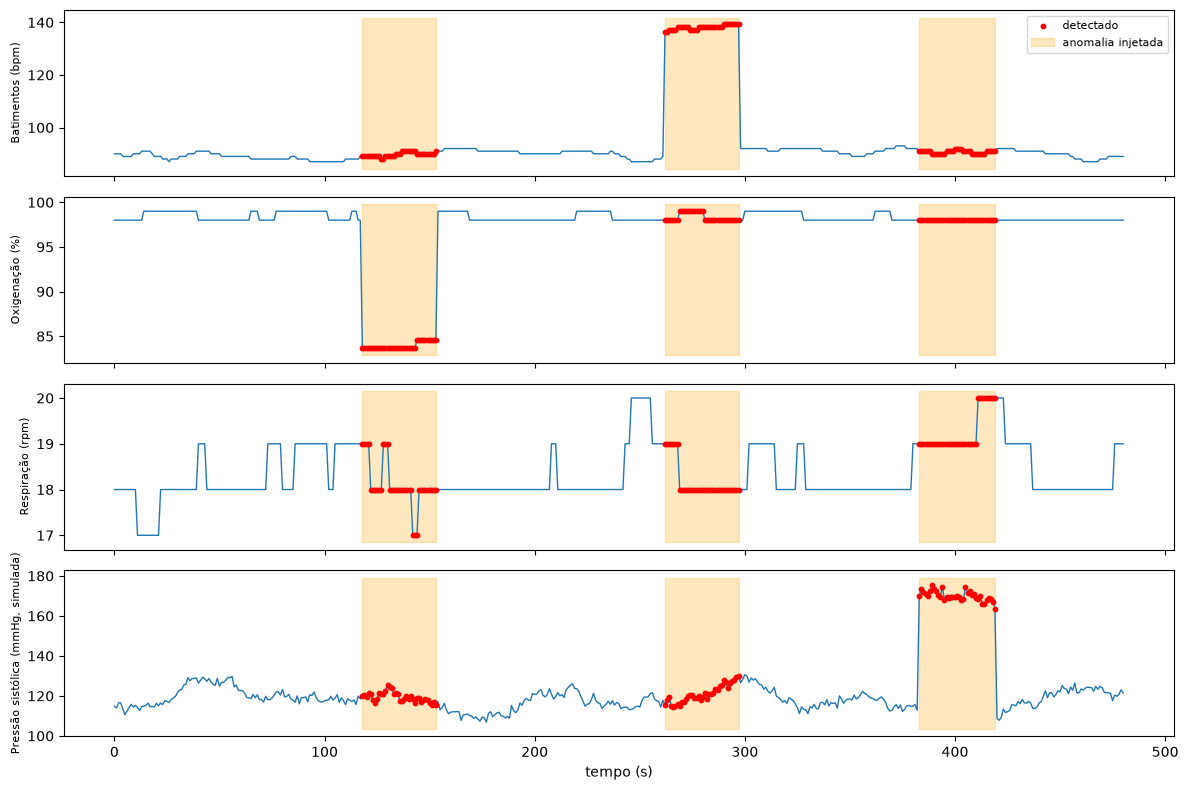

In [7]:
exemplo = teste[10]
marcado = detector.avaliar_serie(exemplo)

fig, eixos = plt.subplots(4, 1, figsize=(12, 8), sharex=True)
nomes = {"fc": "Batimentos (bpm)", "spo2": "Oxigenação (%)", "fr": "Respiração (rpm)", "pas": "Pressão sistólica (mmHg, simulada)"}
for eixo, sinal in zip(eixos, SINAIS):
    eixo.plot(exemplo["tempo_s"], exemplo[sinal], linewidth=1)
    eixo.scatter(exemplo.loc[marcado, "tempo_s"], exemplo.loc[marcado, sinal], color="red", s=10, zorder=3, label="detectado")
    eixo.fill_between(exemplo["tempo_s"], *eixo.get_ylim(), where=exemplo["anomalia_real"], color="orange", alpha=0.25, label="anomalia injetada")
    eixo.set_ylabel(nomes[sinal], fontsize=8)
eixos[0].legend(loc="upper right", fontsize=8)
eixos[-1].set_xlabel("tempo (s)")
plt.tight_layout()
plt.show()

### 1.6 Monitoramento amostra a amostra

No uso real o detector recebe **uma leitura por segundo**. Um episódio contínuo gera um único evento
(no instante em que começa), para não inundar a equipe com alertas repetidos.

In [8]:
detector.reiniciar()
eventos = []
for linha in exemplo.itertuples():
    eventos += detector.avaliar_amostra({sinal: getattr(linha, sinal) for sinal in SINAIS}, linha.tempo_s)

pd.DataFrame([{"instante (s)": e.instante, "fonte": e.fonte, "tipo": e.tipo, "severidade": e.severidade, "descrição": e.descricao} for e in eventos])

,instante (s),fonte,tipo,severidade,descrição
0,118,sinais_vitais,limite_clinico,3,"Sinais vitais fora do padrão (SPO2). Leituras: FC 89 bpm, SPO2 84 %, FR 19 rpm, PAS 120 mmHg"
1,262,sinais_vitais,padrao_anomalo,2,"Sinais vitais fora do padrão (FC). Leituras: FC 136 bpm, SPO2 98 %, FR 19 rpm, PAS 116 mmHg"
2,383,sinais_vitais,padrao_anomalo,2,"Sinais vitais fora do padrão (PAS). Leituras: FC 91 bpm, SPO2 98 %, FR 19 rpm, PAS 170 mmHg"


In [9]:
Path("models").mkdir(exist_ok=True)
detector.reiniciar()
joblib.dump(detector, "models/sinais_vitais.joblib")
exemplo.to_csv("data/amostras/sinais_vitais_demo.csv", index=False)
print("Detector salvo em models/sinais_vitais.joblib")
print("Série de demonstração salva em data/amostras/sinais_vitais_demo.csv")

Detector salvo em models/sinais_vitais.joblib
Série de demonstração salva em data/amostras/sinais_vitais_demo.csv


## 2. Prescrições

Tabela **sintética** com três pacientes (`data/prescricoes.csv`). Regras:

- **Mudança brusca de dose:** variação acima de 50% entre prescrições seguidas do mesmo medicamento
  (severidade 2; severidade 3 se a dose mais que dobrou).
- **Troca inesperada de tratamento:** dois ou mais medicamentos novos iniciados em menos de 24 h
  (os da prescrição de entrada não contam).

In [10]:
prescricoes = pd.read_csv("data/prescricoes.csv", parse_dates=["data_hora"])
prescricoes.pivot_table(index="data_hora", columns=["paciente_id", "medicamento"], values="dose_mg").astype(object).fillna("")

paciente_id              P001                   P002                  P003  \
medicamento         losartana sinvastatina enalapril furosemida amiodarona   
data_hora                                                                    
2026-03-02 08:00:00      50.0         20.0                                   
2026-03-02 09:00:00                             10.0       40.0              
2026-03-02 10:00:00                                                          
2026-03-03 08:00:00      50.0         20.0                                   
2026-03-03 09:00:00                             10.0       40.0              
2026-03-03 10:00:00                                                          
2026-03-04 08:00:00      50.0         20.0                                   
2026-03-04 09:00:00                             10.0       80.0              
2026-03-04 10:00:00                                                          
2026-03-04 14:00:00                                                  200.0   
2026-03-04 22:00:00                                                          
2026-03-05 08:00:00      50.0         20.0                                   
2026-03-05 09:00:00                             12.5       80.0              
2026-03-05 10:00:00                                                          

paciente_id                                       
medicamento         metoprolol morfina varfarina  
data_hora                                         
2026-03-02 08:00:00                               
2026-03-02 09:00:00                               
2026-03-02 10:00:00       25.0     5.0            
2026-03-03 08:00:00                               
2026-03-03 09:00:00                               
2026-03-03 10:00:00       25.0     5.0            
2026-03-04 08:00:00                               
2026-03-04 09:00:00                               
2026-03-04 10:00:00       25.0    15.0            
2026-03-04 14:00:00                               
2026-03-04 22:00:00                          5.0  
2026-03-05 08:00:00                               
2026-03-05 09:00:00                               
2026-03-05 10:00:00       25.0    15.0

In [11]:
eventos_prescricao = detectar_anomalias_prescricao(prescricoes)
pd.DataFrame([{"tipo": e.tipo, "severidade": e.severidade, "horas desde a entrada": e.instante / 3600, "descrição": e.descricao} for e in eventos_prescricao])

,tipo,severidade,horas desde a entrada,descrição
0,mudanca_brusca_de_dose,2,48.0,Paciente P002: dose de furosemida passou de 40 mg para 80 mg (100% de variação)
1,mudanca_brusca_de_dose,3,48.0,Paciente P003: dose de morfina passou de 5 mg para 15 mg (200% de variação)
2,troca_inesperada_de_tratamento,2,60.0,Paciente P003: medicamentos novos iniciados em menos de 24 h: amiodarona e varfarina


O paciente P001 (tratamento estável) não gera nenhum evento. O ajuste pequeno do enalapril em P002
(de 10 para 12,5 mg, 25%) também não: fica abaixo do limite de 50%.

## 3. Movimentação do paciente

A trajetória vem do YOLOv8 (`src/video/detector.py`): posição do centro da pessoa em cada quadro, de 0 a 1.
Regras:

- **Imobilidade:** sem se deslocar por mais de 10 s.
- **Fora da área:** centro da pessoa fora da zona esperada do quadro.
- **Paciente ausente:** ninguém no quadro por mais de 5 s.

Abaixo, uma trajetória **simulada** de 60 s para mostrar as três regras. A aplicação sobre vídeo real está no notebook 03.

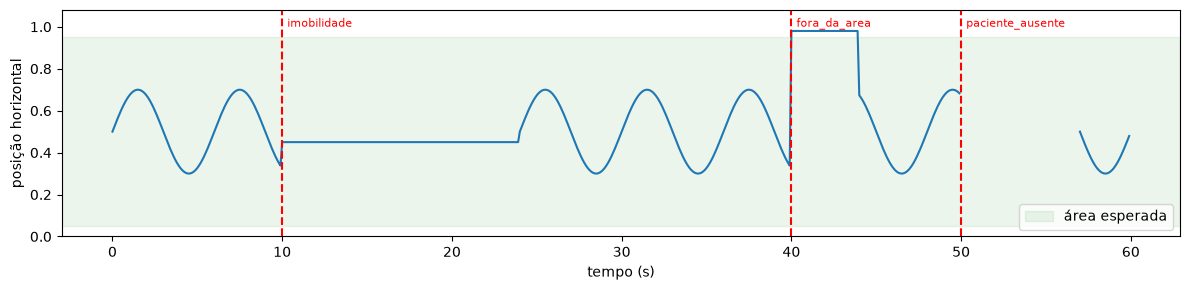

,instante (s),tipo,severidade,descrição
0,10.0,imobilidade,2,Paciente sem se mover por 14 s
1,40.0,fora_da_area,2,Paciente fora da área esperada por 4 s
2,50.0,paciente_ausente,2,Nenhuma pessoa detectada por 7 s


In [12]:
fps = 10
t = np.arange(60 * fps) / fps
x = 0.5 + 0.2 * np.sin(2 * np.pi * t / 6)   # paciente andando de um lado para o outro
x[(t >= 10) & (t < 24)] = 0.45               # parado por 14 s
x[(t >= 40) & (t < 44)] = 0.98               # encostado na borda, fora da área
pessoas = np.ones(len(t), dtype=int)
pessoas[(t >= 50) & (t < 57)] = 0            # ninguém no quadro por 7 s

trajetoria = pd.DataFrame({
    "frame": np.arange(len(t)), "tempo_s": t,
    "x_centro": np.where(pessoas > 0, x, np.nan), "y_centro": np.where(pessoas > 0, 0.5, np.nan),
    "largura": 0.2, "altura": 0.6, "n_pessoas": pessoas,
})
eventos_mov = detectar_anomalias_movimentacao(trajetoria)

fig, eixo = plt.subplots(figsize=(12, 3))
eixo.plot(trajetoria["tempo_s"], trajetoria["x_centro"])
eixo.axhspan(0.05, 0.95, color="green", alpha=0.08, label="área esperada")
for e in eventos_mov:
    eixo.axvline(e.instante, color="red", linestyle="--")
    eixo.text(e.instante + 0.3, 1.0, e.tipo, color="red", fontsize=8)
eixo.set(xlabel="tempo (s)", ylabel="posição horizontal", ylim=(0, 1.08))
eixo.legend(loc="lower right")
plt.tight_layout()
plt.show()

pd.DataFrame([{"instante (s)": e.instante, "tipo": e.tipo, "severidade": e.severidade, "descrição": e.descricao} for e in eventos_mov])